# German Traffic Sign Recognition Using Deep Learning

**Course:** AAI-521 Computer Vision

**Dataset:** German Traffic Sign Recognition Benchmark (GTSRB)

## Project Overview

This project focuses on classifying German traffic signs using computer vision and deep learning. The GTSRB dataset contains images from 43 different traffic sign classes.

The project will compare two deep learning models: a custom Convolutional Neural Network (CNN) and a pretrained MobileNetV2 model. Both models will be trained and evaluated to compare their classification performance.

## Project Objectives

The main objective of this project is to develop and evaluate deep learning models for traffic sign recognition.

The project includes the following tasks:

- Loading and exploring the dataset
- Examining class distributions and image dimensions
- Checking data quality
- Resizing and normalizing images
- Creating training, validation, and testing datasets
- Applying data augmentation techniques
- Developing and training a custom CNN and MobileNetV2
- Evaluating model performance using accuracy, precision, recall, and F1-score
- Comparing model performance and analyzing the results

## Dataset Source

**German Traffic Sign Recognition Benchmark (GTSRB)**

https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

In [1]:
# Install the libraries needed for the project
!pip -q install kagglehub opencv-python-headless seaborn scikit-learn

In [2]:
# Import the libraries
import os
import random
import shutil
from pathlib import Path

import kagglehub
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display

# Set the random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Set the image size and batch size
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
NUM_CLASSES = 43

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


## 1. Dataset Loading

The GTSRB dataset will be downloaded directly from Kaggle using
the KaggleHub library.

The dataset includes training and testing images along with CSV
files containing image information and class labels.

The dataset structure will be checked before starting the analysis.

In [3]:
# Download the GTSRB dataset
dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

# Set the dataset directory
DATA_DIR = Path(dataset_path)

print("Dataset downloaded successfully!")
print("Dataset location:", DATA_DIR)

100%|██████████| 612M/612M [00:09<00:00, 67.7MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1


In [4]:
# Display the files and folders
print("Dataset contents:\n")

for item in sorted(DATA_DIR.iterdir()):
    print(item.name)

Dataset contents:

Meta
Meta.csv
Test
Test.csv
Train
Train.csv
meta
test
train


In [5]:
# Load the training and testing CSV files
train_df = pd.read_csv(DATA_DIR / "Train.csv")
test_df = pd.read_csv(DATA_DIR / "Test.csv")

# Display dataset sizes
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

# Display sample records
display(train_df.head())

Training dataset: (39209, 8)
Testing dataset: (12630, 8)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [6]:
# Display dataset information
print("Training dataset information:")
train_df.info()

# Check the columns
print("\nColumns:")
print(train_df.columns.tolist())

# Count images and classes
print("\nTraining images:", len(train_df))
print("Testing images:", len(test_df))
print("Number of classes:", train_df["ClassId"].nunique())

# Display class labels
print("\nClass IDs:")
print(sorted(train_df["ClassId"].unique()))

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39209 entries, 0 to 39208
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Width    39209 non-null  int64 
 1   Height   39209 non-null  int64 
 2   Roi.X1   39209 non-null  int64 
 3   Roi.Y1   39209 non-null  int64 
 4   Roi.X2   39209 non-null  int64 
 5   Roi.Y2   39209 non-null  int64 
 6   ClassId  39209 non-null  int64 
 7   Path     39209 non-null  object
dtypes: int64(7), object(1)
memory usage: 2.4+ MB

Columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Training images: 39209
Testing images: 12630
Number of classes: 43

Class IDs:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np

## 2. Exploratory Data Analysis (EDA)

Exploratory data analysis helps us understand the dataset before
preprocessing and model training.

This section examines the number of images in each class,
sample traffic sign images, and image dimensions.

The analysis will help identify differences between classes
and possible preprocessing requirements.

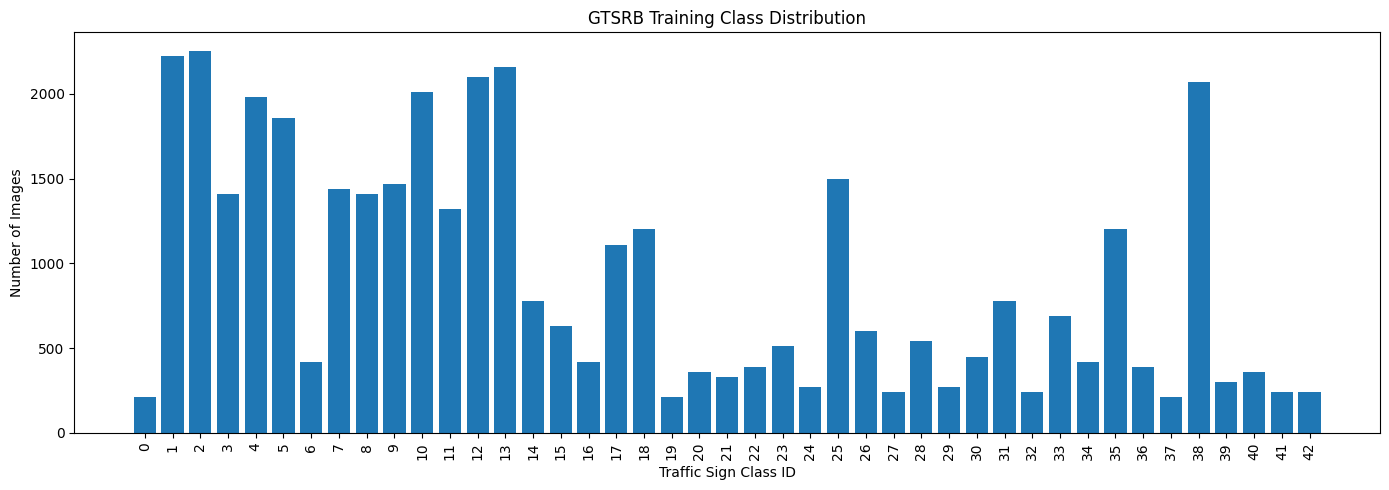

Minimum images per class: 210
Maximum images per class: 2250
Average images per class: 911.84


In [7]:
# Count the images in each class
class_counts = train_df["ClassId"].value_counts().sort_index()

# Plot the class distribution
plt.figure(figsize=(14, 5))

plt.bar(class_counts.index, class_counts.values)

plt.title("GTSRB Training Class Distribution")
plt.xlabel("Traffic Sign Class ID")
plt.ylabel("Number of Images")
plt.xticks(class_counts.index, rotation=90)

plt.tight_layout()
plt.show()

# Display class statistics
print("Minimum images per class:", class_counts.min())
print("Maximum images per class:", class_counts.max())
print("Average images per class:", round(class_counts.mean(), 2))

### Class Distribution

The training dataset contains 43 traffic sign classes with different numbers of images. The minimum number of images per class is 210, the maximum is 2,250, and the average is 911.84 images per class.

The graph shows that the dataset is imbalanced because some traffic sign classes have significantly more images than others. This may affect model performance, as classes with fewer images may be more difficult for the models to recognize.

This class distribution will be considered when evaluating the custom CNN and MobileNetV2 models.

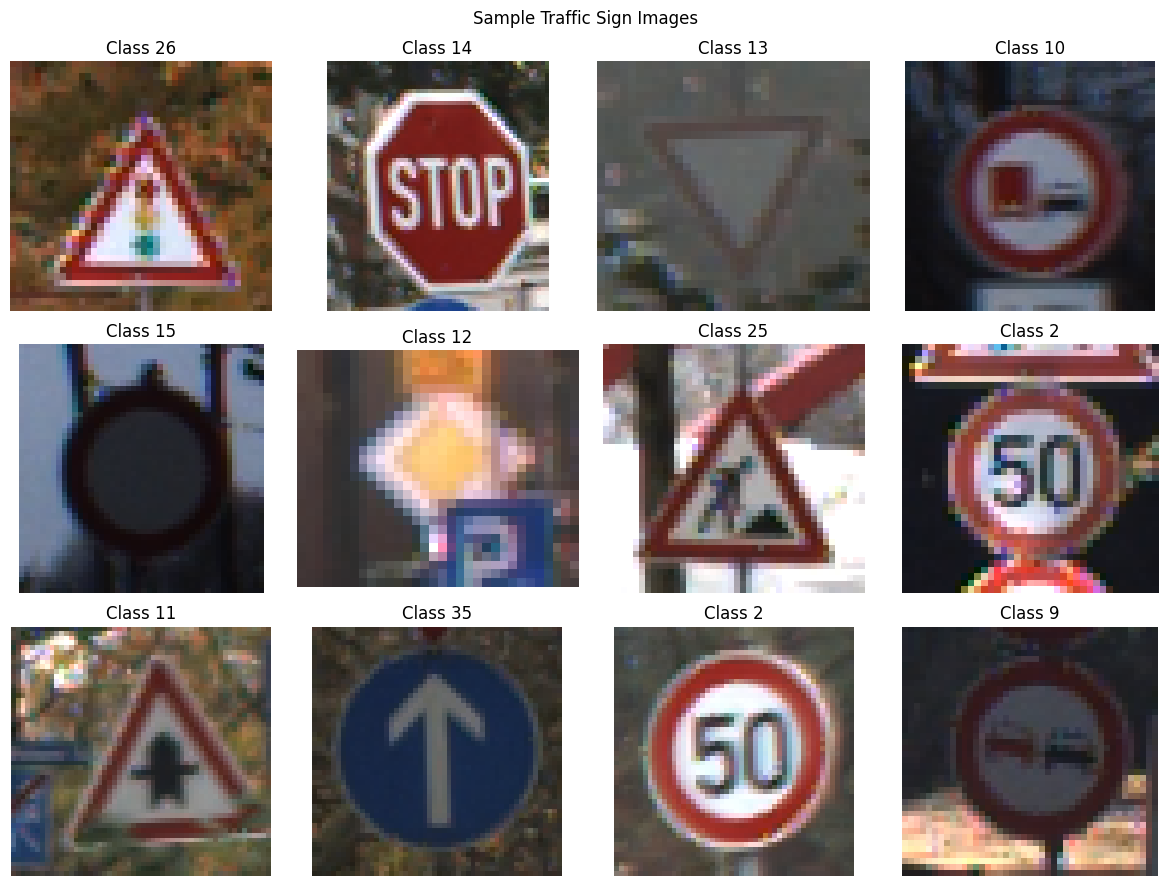

In [8]:
# Select 12 random training images
samples = train_df.sample(12, random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):

    # Load the image
    image_path = DATA_DIR / row["Path"]
    image = cv2.imread(str(image_path))

    if image is not None:
        # Convert BGR to RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image)

    ax.set_title(f"Class {row['ClassId']}")
    ax.axis("off")

plt.suptitle("Sample Traffic Sign Images")
plt.tight_layout()
plt.show()

### Sample Images

The sample images show different traffic sign categories
included in the dataset.

The signs have different shapes, colors, and symbols.
Some images may also have differences in lighting,
image quality, and viewing angles.

These variations are important for image classification.

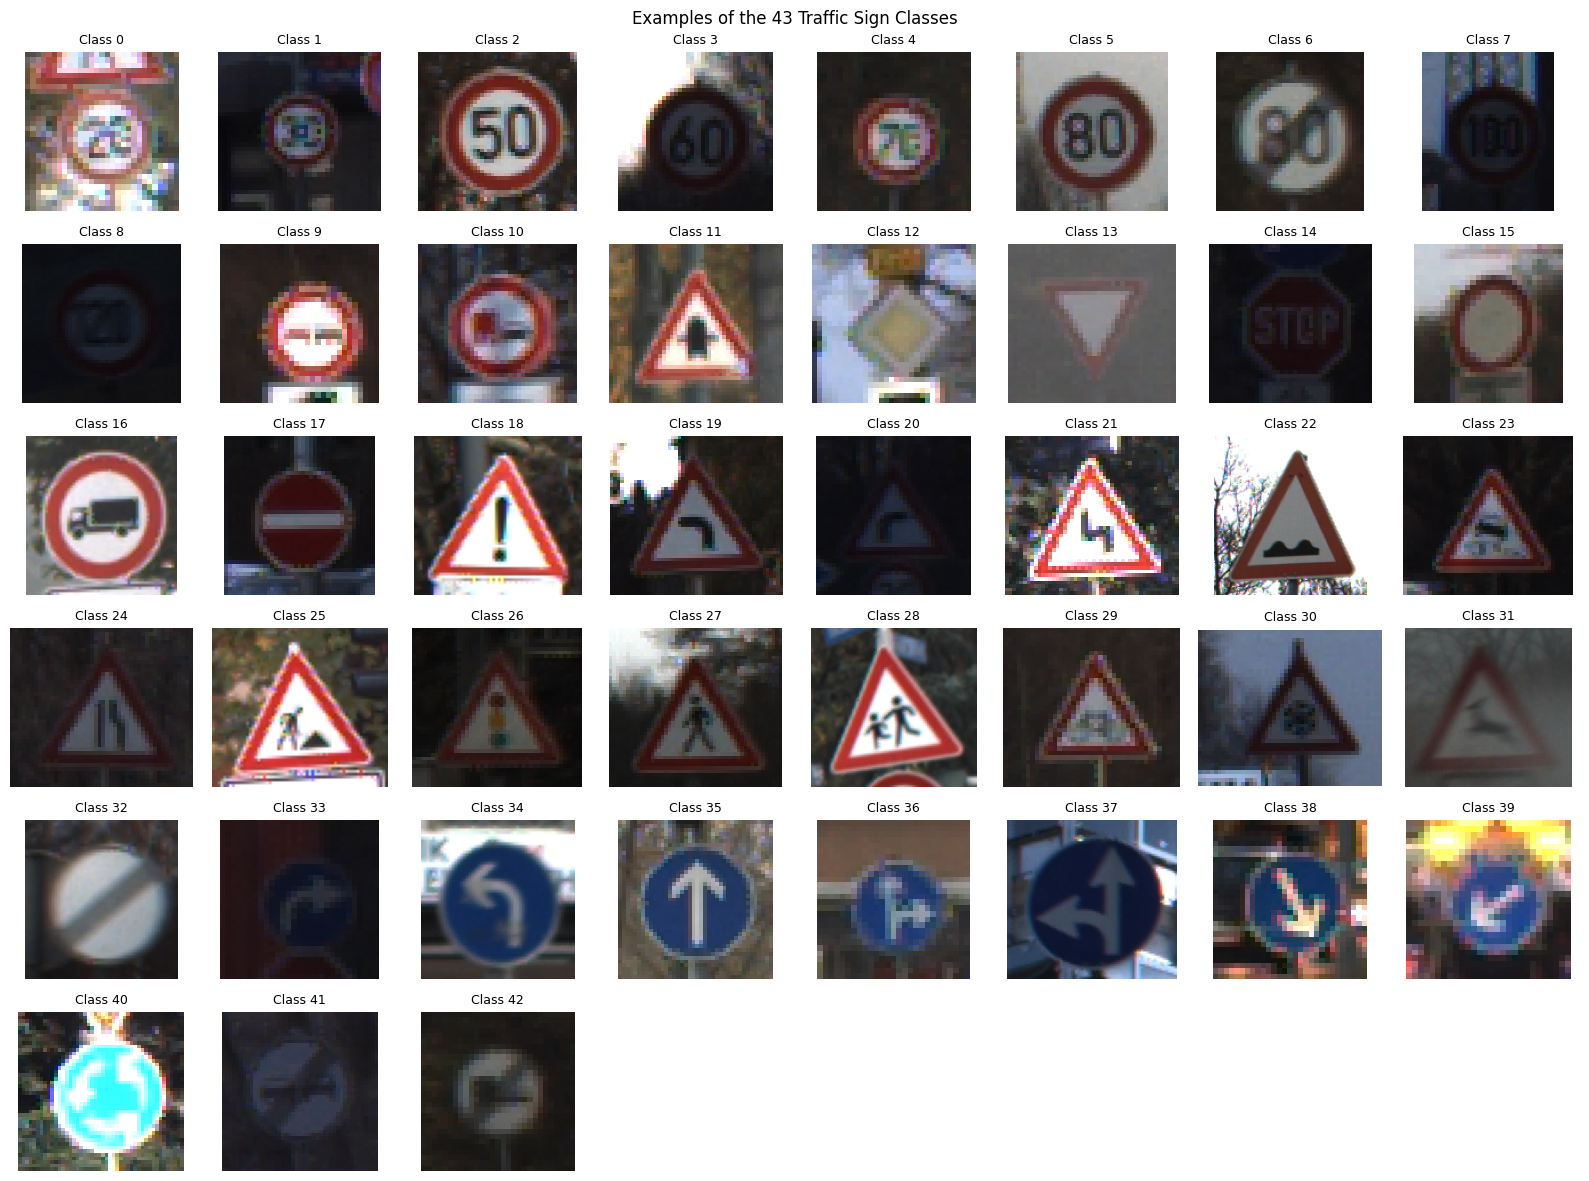

In [9]:
# Select one image from each class
class_samples = (
    train_df.groupby("ClassId")
    .sample(n=1, random_state=SEED)
    .sort_values("ClassId")
)

fig, axes = plt.subplots(6, 8, figsize=(16, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, (_, row) in zip(axes.flat, class_samples.iterrows()):

    image_path = DATA_DIR / row["Path"]
    image = cv2.imread(str(image_path))

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image)

    ax.set_title(f"Class {row['ClassId']}", fontsize=9)

plt.suptitle("Examples of the 43 Traffic Sign Classes")
plt.tight_layout()
plt.show()

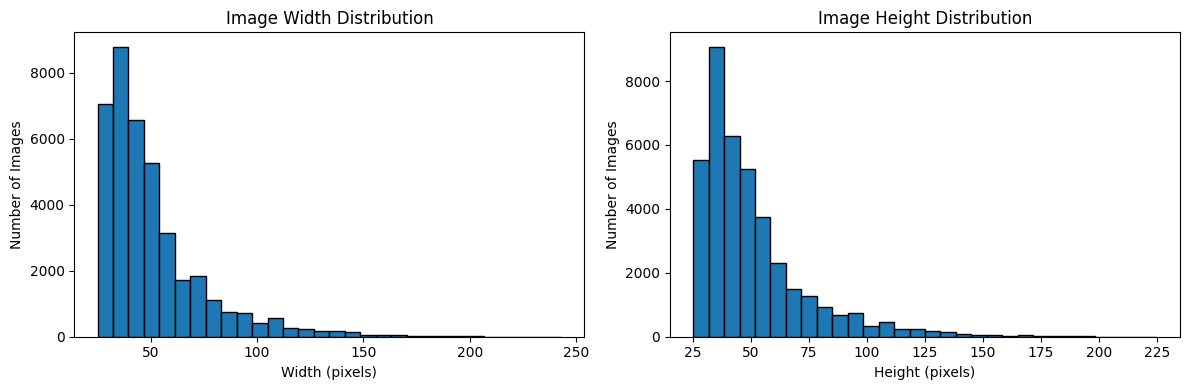

Minimum width: 25
Maximum width: 243
Minimum height: 25
Maximum height: 225


In [10]:
# Get the image widths and heights
widths = train_df["Width"]
heights = train_df["Height"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot image widths
axes[0].hist(widths, bins=30, edgecolor="black")
axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Number of Images")

# Plot image heights
axes[1].hist(heights, bins=30, edgecolor="black")
axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

print("Minimum width:", widths.min())
print("Maximum width:", widths.max())
print("Minimum height:", heights.min())
print("Maximum height:", heights.max())

### Image Dimensions

The training images have different widths and heights. The minimum width and height are both 25 pixels, while the maximum width is 243 pixels and the maximum height is 225 pixels.

The graphs show that most images have smaller dimensions, while fewer images have larger dimensions.

To create consistent inputs for both models, all images will be resized to 128 × 128 pixels during preprocessing. This will allow the custom CNN and MobileNetV2 models to use the same image dimensions.

## 3. Data Quality Checks

Before preprocessing, the dataset will be checked for
missing values, duplicate image paths, and unreadable images.

These checks help identify problems that could affect
model training.

Invalid records will be removed if necessary.

In [11]:
# Check for missing values
print("Missing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in testing data:")
print(test_df.isnull().sum())

# Check duplicate image paths
print("\nDuplicate training paths:",
      train_df["Path"].duplicated().sum())

print("Duplicate testing paths:",
      test_df["Path"].duplicated().sum())

# Check class labels
expected_classes = set(range(NUM_CLASSES))
actual_classes = set(train_df["ClassId"].unique())

print("\nMissing class IDs:",
      sorted(expected_classes - actual_classes))

Missing values in training data:
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Missing values in testing data:
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Duplicate training paths: 0
Duplicate testing paths: 0

Missing class IDs: []


In [12]:
# Create a function to check image files
def check_images(dataframe):

    invalid_images = []

    for path in dataframe["Path"]:
        image_path = DATA_DIR / path

        # Try to read the image
        image = cv2.imread(str(image_path))

        if image is None:
            invalid_images.append(path)

    return invalid_images


# Check training and testing images
invalid_train = check_images(train_df)
invalid_test = check_images(test_df)

print("Unreadable training images:", len(invalid_train))
print("Unreadable testing images:", len(invalid_test))

Unreadable training images: 0
Unreadable testing images: 0


In [13]:
# Remove missing and duplicate records
train_df = train_df.dropna(
    subset=["Path", "ClassId"]
).drop_duplicates(subset=["Path"]).copy()

test_df = test_df.dropna(
    subset=["Path", "ClassId"]
).drop_duplicates(subset=["Path"]).copy()

# Remove unreadable images
train_df = train_df[
    ~train_df["Path"].isin(invalid_train)
].reset_index(drop=True)

test_df = test_df[
    ~test_df["Path"].isin(invalid_test)
].reset_index(drop=True)

print("Cleaned training images:", len(train_df))
print("Cleaned testing images:", len(test_df))

Cleaned training images: 39209
Cleaned testing images: 12630


### Data Quality Summary

The training and testing datasets were checked for missing values, duplicate image paths, and unreadable images.

The results showed no missing values, duplicate image paths, or unreadable images. Therefore, no images needed to be removed during cleaning.

After cleaning, the dataset contains 39,209 training images and 12,630 testing images. These results indicate that the dataset is ready for preprocessing and splitting.

## 4. Image Preprocessing

Image preprocessing prepares the images for classification.

The preprocessing steps include:

1. Reading the images using OpenCV
2. Converting images from BGR to RGB
3. Resizing images to 128 × 128 pixels
4. Converting pixel values to floating-point numbers
5. Normalizing pixel values to the range of 0 to 1

The same image size will be used for both models.

In [14]:
# Set the image size
IMG_SIZE = (128, 128)

def preprocess_image(image_path):

    # Read the image
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize the image
    image = cv2.resize(image, IMG_SIZE)

    # Normalize the pixel values
    image = image.astype(np.float32) / 255.0

    return image

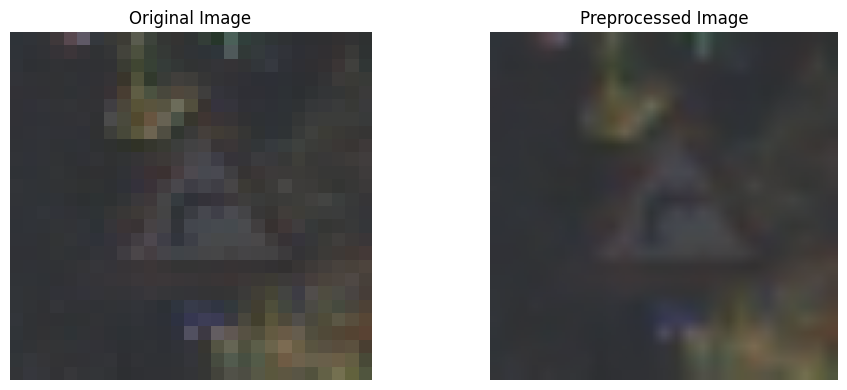

Original shape: (26, 27, 3)
Processed shape: (128, 128, 3)
Minimum pixel value: 0.14901961
Maximum pixel value: 0.47843137


In [15]:
# Select one training image
sample_path = DATA_DIR / train_df.iloc[0]["Path"]

# Load the original image
original = cv2.imread(str(sample_path))
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Preprocess the image
processed = preprocess_image(sample_path)

# Display the comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(original)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(processed)
axes[1].set_title("Preprocessed Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original shape:", original.shape)
print("Processed shape:", processed.shape)
print("Minimum pixel value:", processed.min())
print("Maximum pixel value:", processed.max())

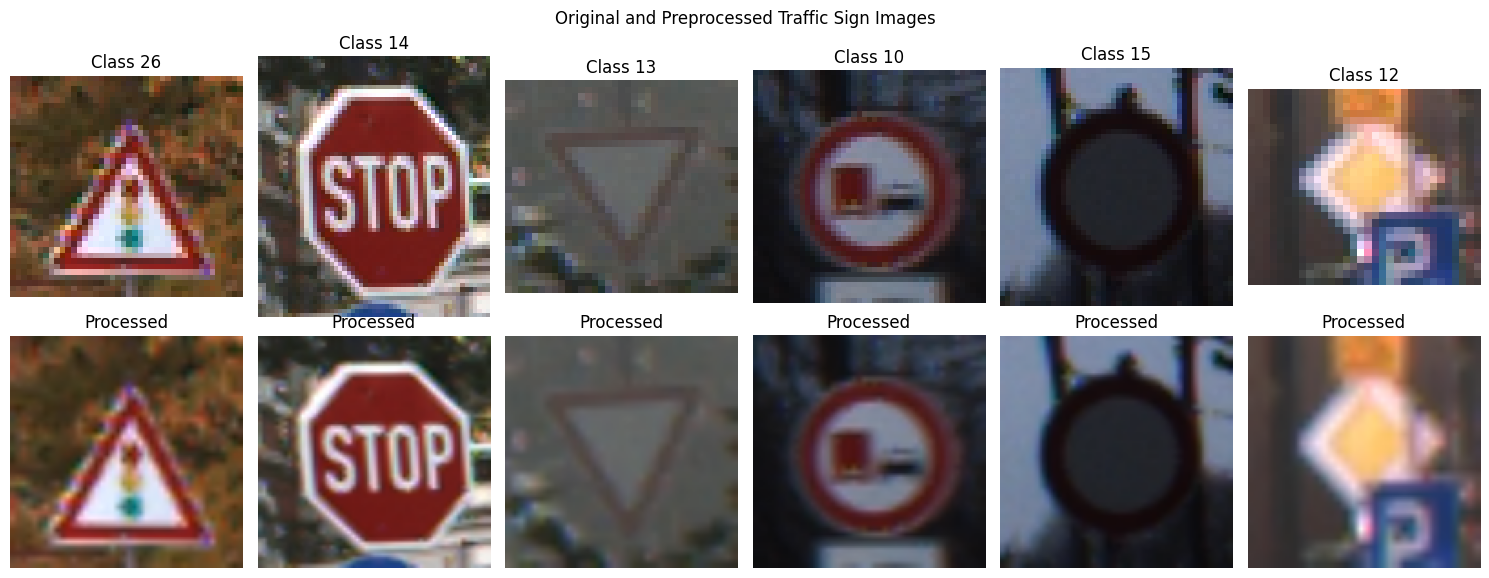

In [16]:
# Select six random images
samples = train_df.sample(6, random_state=SEED)

fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for i, (_, row) in enumerate(samples.iterrows()):

    image_path = DATA_DIR / row["Path"]

    # Load original image
    original = cv2.imread(str(image_path))
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    # Preprocess the image
    processed = preprocess_image(image_path)

    axes[0, i].imshow(original)
    axes[0, i].set_title(f"Class {row['ClassId']}")
    axes[0, i].axis("off")

    axes[1, i].imshow(processed)
    axes[1, i].set_title("Processed")
    axes[1, i].axis("off")

plt.suptitle("Original and Preprocessed Traffic Sign Images")
plt.tight_layout()
plt.show()

### Preprocessing Results

The images were resized to 128 × 128 pixels and converted
to RGB format.

Pixel values were normalized to the range of 0 to 1.

The original and preprocessed images were compared to
check whether the traffic signs remained recognizable.

These preprocessing steps provide a consistent input
format for model development.

## 5. Dataset Splitting

The original training dataset will be divided into training and validation sets.

A group-aware splitting method will be used to keep related images from the same traffic sign sequence together. This helps reduce data leakage between training and validation.

Approximately 80% of the original training data will be used for training and 20% for validation. The exact proportions may vary because the images are split by groups.

The official GTSRB test dataset will remain separate and will be used for final model evaluation.

Both classification models will use the same dataset splits to support a fair comparison.

In [18]:
# Identify related traffic sign image sequences
def get_sequence_id(path):
    image_path = Path(path)

    # Get the sequence name without the frame number
    sequence_name = image_path.stem.rsplit("_", 1)[0]

    # Include the class folder to keep groups separate
    return str(image_path.parent / sequence_name)


# Create a temporary sequence column
train_df["SequenceId"] = train_df["Path"].apply(
    get_sequence_id
)


# Create a group-aware split within each class
train_parts = []
val_parts = []

for class_id, class_df in train_df.groupby("ClassId"):

    # Keep related image sequences together
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=SEED
    )

    train_idx, val_idx = next(
        splitter.split(
            class_df,
            groups=class_df["SequenceId"]
        )
    )

    train_parts.append(class_df.iloc[train_idx])
    val_parts.append(class_df.iloc[val_idx])

# Combine all classes into training and validation sets
train_split = pd.concat(train_parts).sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

val_split = pd.concat(val_parts).sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

# Remove temporary sequence column
train_split = train_split.drop(columns=["SequenceId"])
val_split = val_split.drop(columns=["SequenceId"])

# Display results
print("Training images:", len(train_split))
print("Validation images:", len(val_split))
print("Testing images:", len(test_df))

print("Training classes:", train_split["ClassId"].nunique())
print("Validation classes:", val_split["ClassId"].nunique())

# Verify all classes are included
assert train_split["ClassId"].nunique() == NUM_CLASSES
assert val_split["ClassId"].nunique() == NUM_CLASSES

print("Dataset splitting completed successfully!")

Training images: 30869
Validation images: 8340
Testing images: 12630
Training classes: 43
Validation classes: 43
Dataset splitting completed successfully!


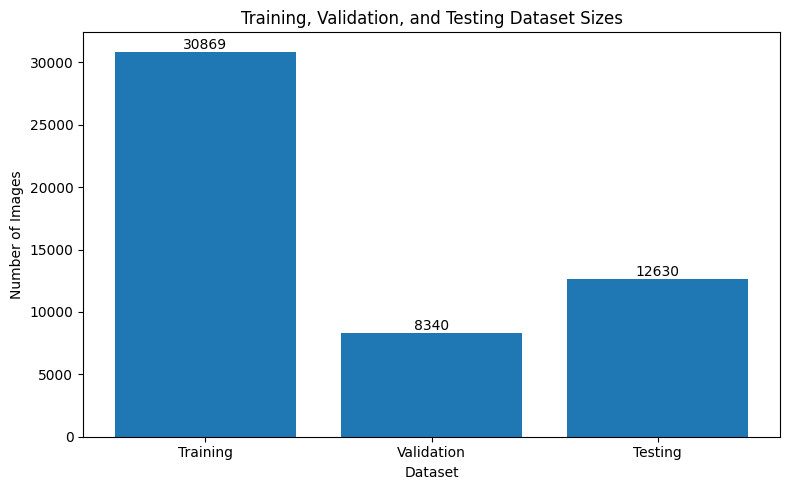

In [19]:
# Get the number of images in each split
split_names = ["Training", "Validation", "Testing"]

split_sizes = [
    len(train_split),
    len(val_split),
    len(test_df)
]

# Plot the dataset sizes
plt.figure(figsize=(8, 5))

bars = plt.bar(split_names, split_sizes)

plt.title("Training, Validation, and Testing Dataset Sizes")
plt.xlabel("Dataset")
plt.ylabel("Number of Images")

# Display the counts above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

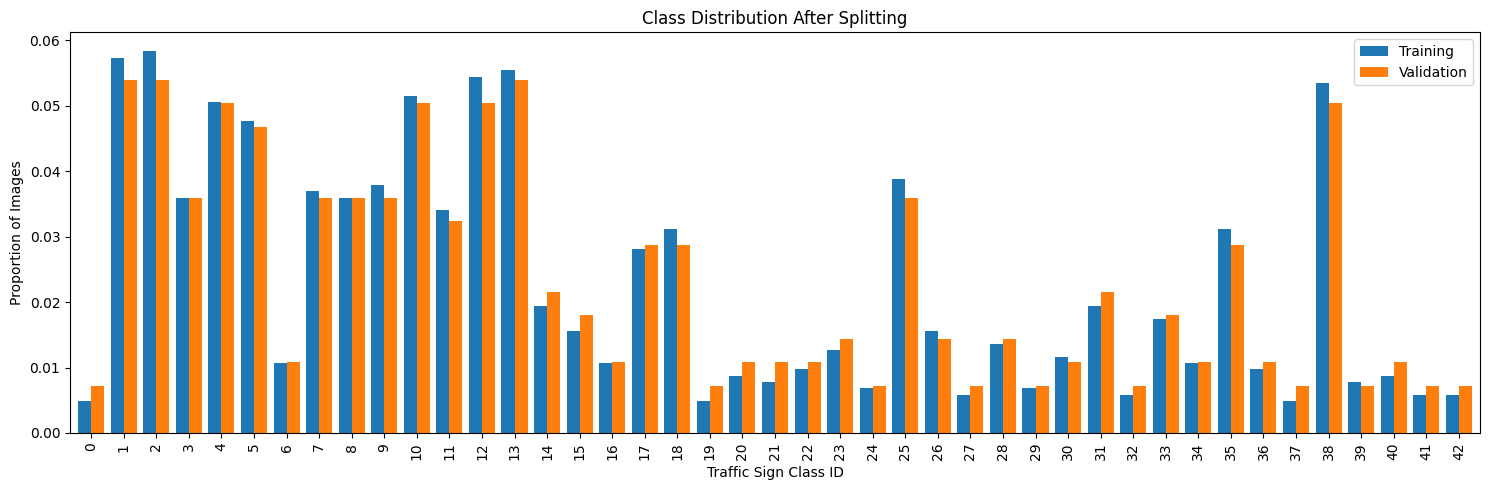

In [20]:
# Calculate class proportions
train_props = (
    train_split["ClassId"]
    .value_counts(normalize=True)
    .sort_index()
)

val_props = (
    val_split["ClassId"]
    .value_counts(normalize=True)
    .sort_index()
)

# Create a comparison table
comparison_df = pd.DataFrame({
    "Training": train_props,
    "Validation": val_props
})

# Plot the proportions
comparison_df.plot(
    kind="bar",
    figsize=(15, 5),
    width=0.8
)

plt.title("Class Distribution After Splitting")
plt.xlabel("Traffic Sign Class ID")
plt.ylabel("Proportion of Images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [21]:
# Get the image paths in each split
train_paths = set(train_split["Path"])
val_paths = set(val_split["Path"])
test_paths = set(test_df["Path"])

# Check for overlapping paths
print("Train/Validation overlap:",
      len(train_paths & val_paths))

print("Train/Test overlap:",
      len(train_paths & test_paths))

print("Validation/Test overlap:",
      len(val_paths & test_paths))

# Verify the training and validation classes
print("\nTraining classes:",
      train_split["ClassId"].nunique())

print("Validation classes:",
      val_split["ClassId"].nunique())

print("Testing classes:",
      test_df["ClassId"].nunique())


# Check for overlapping image sequences
train_sequences = set(
    train_split["Path"].apply(get_sequence_id)
)

val_sequences = set(
    val_split["Path"].apply(get_sequence_id)
)

# Find any sequences shared between the two datasets
sequence_overlap = train_sequences & val_sequences

print("Overlapping sequences:", len(sequence_overlap))

# Make sure no sequences overlap
assert len(sequence_overlap) == 0

print("No overlapping sequences detected!")

Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0

Training classes: 43
Validation classes: 43
Testing classes: 43
Overlapping sequences: 0
No overlapping sequences detected!


### Dataset Split Results

The original training dataset was divided into training and validation sets using group-aware splitting within each traffic sign class.

The final split contains 30,869 training images and 8,340 validation images. The official test dataset contains 12,630 images and was kept separate for final model evaluation.

All three datasets contain all 43 traffic sign classes. The image paths were checked for overlap, and no overlapping paths were found between the datasets.

The training and validation sets were also checked for overlapping image sequences. The results showed zero overlapping sequences, which helps reduce the risk of data leakage.

Both the custom CNN and MobileNetV2 models will use the same dataset splits to support a fair comparison.

## 6. Data Augmentation

Data augmentation creates different versions of training
images by applying small transformations.

For this project, the following techniques will be explored:

- Small rotations
- Zooming
- Brightness changes

These transformations can help models recognize traffic
signs under different lighting and viewing conditions.

Data augmentation will be demonstrated in this notebook and can be applied to training images during model development. Validation and testing images will not receive random augmentation.

Horizontal and vertical flipping will not be used because
they can change the meaning of traffic signs.

In [22]:
# Create augmentation layers
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomBrightness(
        factor=0.15,
        value_range=(0.0, 1.0)
    )
], name="data_augmentation")

print("Data augmentation layers created!")

Data augmentation layers created!


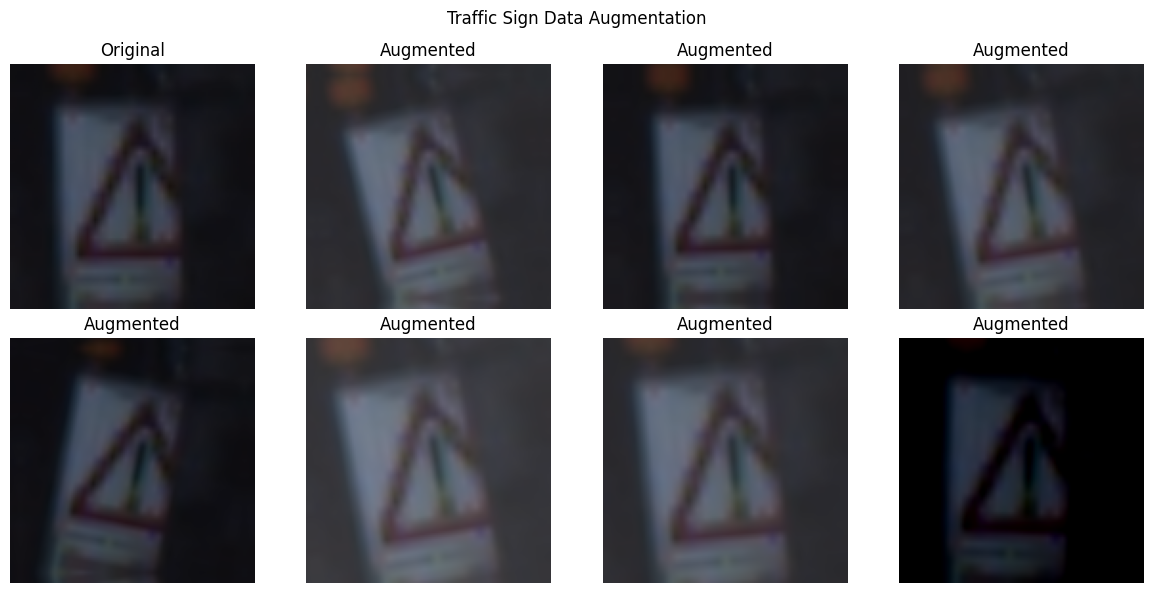

In [23]:
# Select one image
sample_path = DATA_DIR / train_split.iloc[0]["Path"]

# Preprocess the image
sample_image = preprocess_image(sample_path)

# Add a batch dimension
sample_batch = np.expand_dims(sample_image, axis=0)

# Display original and augmented images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

axes[0, 0].imshow(sample_image)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

for ax in axes.flat[1:]:

    # Apply augmentation
    augmented = data_augmentation(
        sample_batch,
        training=True
    )[0].numpy()

    # Keep pixel values between 0 and 1
    augmented = np.clip(augmented, 0, 1)

    ax.imshow(augmented)
    ax.set_title("Augmented")
    ax.axis("off")

plt.suptitle("Traffic Sign Data Augmentation")
plt.tight_layout()
plt.show()

### Data Augmentation Results

Data augmentation was explored using small rotations, zooming, and brightness adjustments.

The visualization shows the original traffic sign image alongside several augmented versions. Some images appear slightly rotated, zoomed, brighter, or darker.

These transformations help simulate different real-world conditions, such as changes in camera angles and lighting. Data augmentation may help the models recognize traffic signs under different conditions and reduce overfitting.

The augmentation techniques were demonstrated but have not yet been applied to the training dataset. During model development, augmentation should be applied only to training images, while validation and testing images remain unchanged.

The same augmentation settings can be used when training the custom CNN and MobileNetV2 models to support a fair comparison.

## 7. Preparing the Data for Model Training

The dataset will be prepared using TensorFlow's data pipeline.

The images will be loaded, resized, normalized, and
organized into batches.

The batch size will be set to 32 images.

This approach allows images to be processed in batches
instead of loading the entire dataset into memory.

The prepared data will be used by the team members
developing the classification models.

In [24]:
# Create a function to load and preprocess images
def load_image_tf(path, label):

    # Read the image file
    image = tf.io.read_file(path)

    # Decode the image into RGB format
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set the image shape
    image.set_shape([None, None, 3])

    # Resize the image
    image = tf.image.resize(image, IMG_SIZE)

    # Normalize pixel values
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [25]:
# Create a function for TensorFlow datasets
def create_dataset(dataframe, shuffle=False):

    # Get the full image paths
    paths = [
        str(DATA_DIR / path)
        for path in dataframe["Path"]
    ]

    # Get the class labels
    labels = dataframe["ClassId"].astype("int32").values

    # Create the dataset
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    # Shuffle the training data
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    # Load and preprocess the images
    dataset = dataset.map(
        load_image_tf,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Create batches
    dataset = dataset.batch(BATCH_SIZE)

    # Improve loading performance
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [26]:
# Create the training dataset
train_dataset = create_dataset(
    train_split,
    shuffle=True
)

# Create the validation dataset
val_dataset = create_dataset(
    val_split
)

# Create the testing dataset
test_dataset = create_dataset(
    test_df
)

print("All TensorFlow datasets created successfully!")

All TensorFlow datasets created successfully!


In [27]:
# Get one batch of training images
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

    print("Sample labels:", labels[:10].numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.002756994
Maximum pixel value: 1.0
Sample labels: [13  5  7 31  8  8  2 10 36 30]


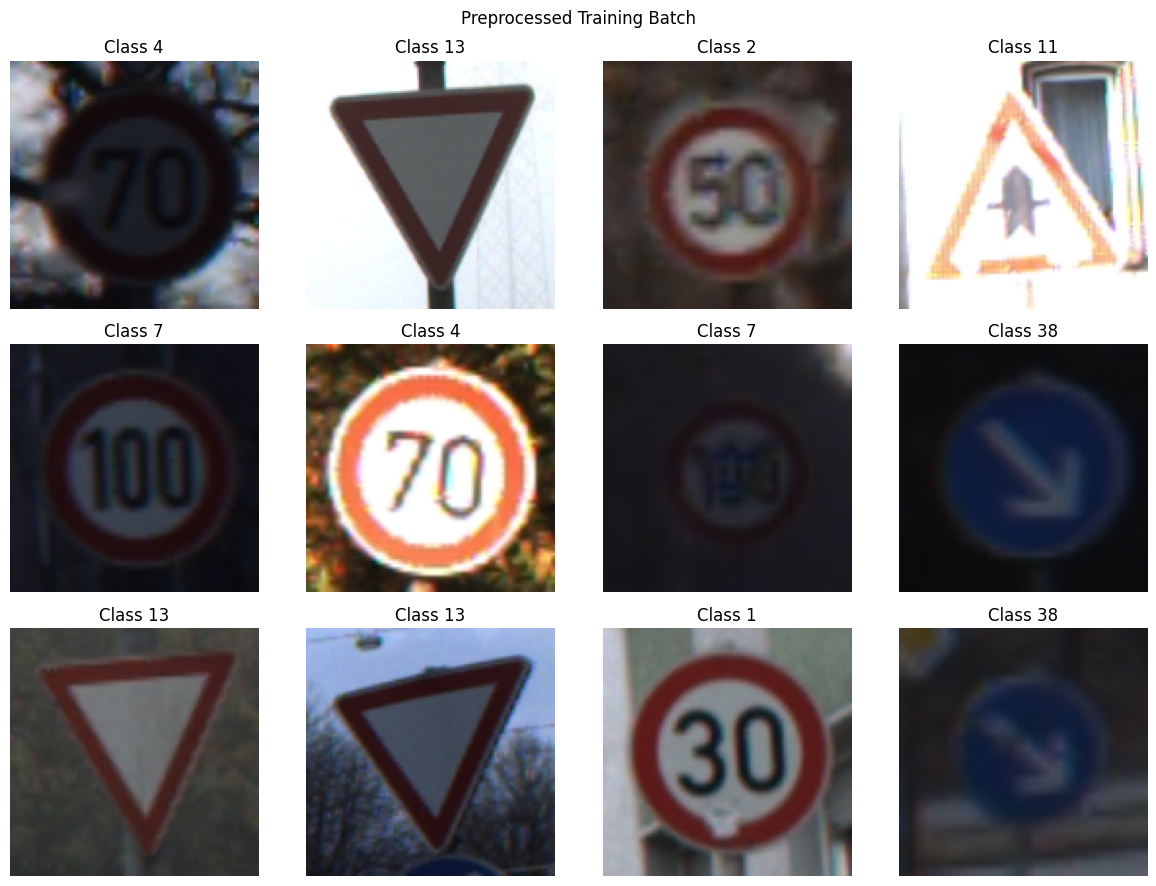

In [28]:
# Display images from one training batch
for images, labels in train_dataset.take(1):

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))

    for i, ax in enumerate(axes.flat):

        ax.imshow(images[i].numpy())
        ax.set_title(f"Class {labels[i].numpy()}")
        ax.axis("off")

    plt.suptitle("Preprocessed Training Batch")
    plt.tight_layout()
    plt.show()

### Final Dataset Verification

The training, validation, and testing datasets were prepared using TensorFlow.

All images were resized to 128 × 128 pixels, converted to RGB format, and normalized to values between 0 and 1. The images were organized into batches of 32, with their corresponding traffic sign class labels.

The visualization shows a sample of the preprocessed training images. The images have consistent dimensions, although some differences in brightness, clarity, and lighting remain from the original dataset.

The custom CNN can use the normalized images directly. The pretrained MobileNetV2 model will require preprocessing compatible with its pretrained weights.

Both models will use the same training, validation, and testing splits to support a consistent comparison.

## 8. Saving the Prepared Dataset

The training, validation, and testing information will
be saved as CSV files.

The class distribution and preprocessing examples
will also be saved as figures.

These files will help the team reproduce the same
dataset preparation steps for both models.

In [29]:
# Create folders for the project outputs
OUTPUT_DIR = Path("/content/GTSRB_Preprocessing_Outputs")

SPLITS_DIR = OUTPUT_DIR / "splits"
FIGURES_DIR = OUTPUT_DIR / "figures"

SPLITS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Output folders created successfully!")

Output folders created successfully!


In [30]:
# Save the training and validation splits
train_split.to_csv(
    SPLITS_DIR / "train_split.csv",
    index=False
)

val_split.to_csv(
    SPLITS_DIR / "val_split.csv",
    index=False
)

# Save the official test information
test_df.to_csv(
    SPLITS_DIR / "test_split.csv",
    index=False
)

# Save the class distribution
class_counts.to_csv(
    OUTPUT_DIR / "class_distribution.csv",
    header=["ImageCount"]
)

print("Dataset splits and statistics saved!")

Dataset splits and statistics saved!


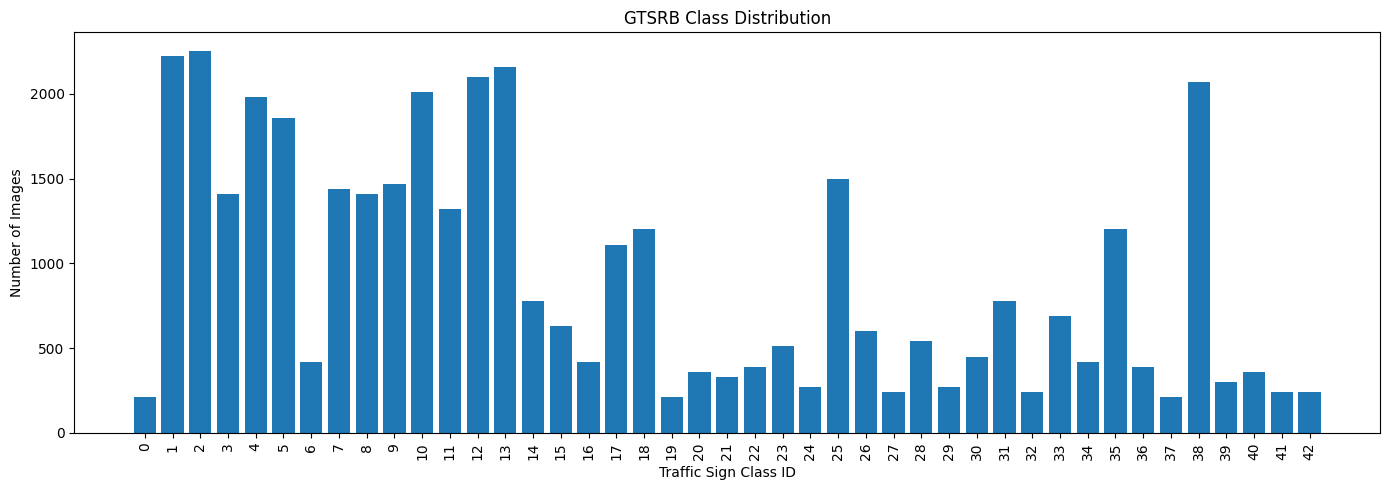

Class distribution graph saved!


In [31]:
# Create the class distribution graph
plt.figure(figsize=(14, 5))

plt.bar(class_counts.index, class_counts.values)

plt.title("GTSRB Class Distribution")
plt.xlabel("Traffic Sign Class ID")
plt.ylabel("Number of Images")
plt.xticks(class_counts.index, rotation=90)

plt.tight_layout()

# Save the graph
plt.savefig(
    FIGURES_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class distribution graph saved!")

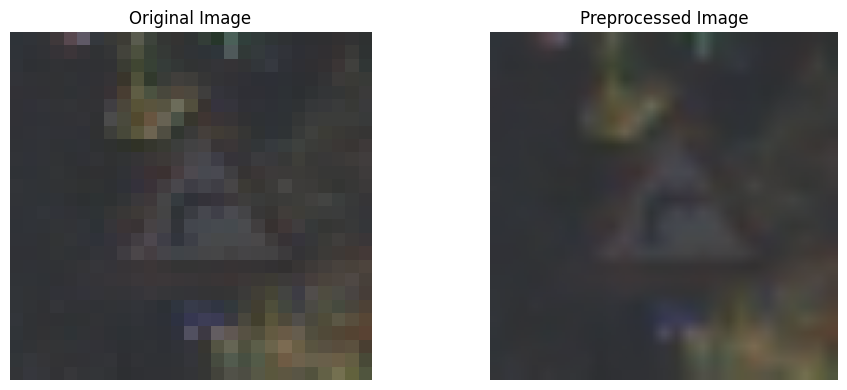

Preprocessing comparison saved!


In [32]:
# Select an example image
sample_path = DATA_DIR / train_df.iloc[0]["Path"]

original = cv2.imread(str(sample_path))
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

processed = preprocess_image(sample_path)

# Create the comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(original)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(processed)
axes[1].set_title("Preprocessed Image")
axes[1].axis("off")

plt.tight_layout()

# Save the comparison
plt.savefig(
    FIGURES_DIR / "preprocessing_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Preprocessing comparison saved!")

In [35]:
settings = {
    "dataset": "GTSRB",
    "source": "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
    "image_size": [128, 128],
    "color_mode": "RGB",
    "normalization": "0 to 1",
    "batch_size": BATCH_SIZE,
    "number_of_classes": NUM_CLASSES,
    "random_seed": SEED,
    "split_method": "GroupShuffleSplit",
    "validation_fraction_of_groups": 0.20,
    "grouping_method": "Class folder and filename sequence prefix",
    "augmentation": {
        "rotation": 0.05,
        "zoom": 0.10,
        "brightness": 0.15,
        "applied_during_preparation": False
    },
    "mobilenetv2_note": (
        "Use preprocessing compatible with pretrained "
        "MobileNetV2 weights during model training."
    ),
    "training_images": len(train_split),
    "validation_images": len(val_split),
    "testing_images": len(test_df)
}
# Save the preprocessing settings as a JSON file
import json

settings_path = OUTPUT_DIR / "preprocessing_settings.json"

with open(settings_path, "w") as file:
    json.dump(settings, file, indent=4)

print("Preprocessing settings saved successfully!")


Preprocessing settings saved successfully!


In [36]:
# Create a ZIP file with the saved outputs
zip_path = shutil.make_archive(
    "/content/GTSRB_Preprocessing_Outputs",
    "zip",
    OUTPUT_DIR
)

print("ZIP file created:", zip_path)

# Download the ZIP file
from google.colab import files

files.download(zip_path)

ZIP file created: /content/GTSRB_Preprocessing_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusion

This notebook focused on dataset preparation, exploratory data analysis, and preprocessing for the German Traffic Sign Recognition Benchmark (GTSRB).

The dataset contains 39,209 training images, 12,630 testing images, and 43 traffic sign classes.

Exploratory data analysis was performed to examine class distributions, sample images, and image dimensions. The results showed differences in the number of images per class and variations in image sizes.

Data quality checks found no missing values, duplicate image paths, or unreadable images.

The images were resized to 128 × 128 pixels, converted to RGB format, and normalized to the range of 0 to 1.

A group-aware splitting method was used to create training and validation datasets while keeping related image sequences together. The official test dataset remained separate.

Data augmentation techniques, including small rotations, zooming, and brightness adjustments, were explored.

Finally, the datasets were prepared using TensorFlow, and the dataset splits, figures, and preprocessing settings were saved.

These steps provide a consistent foundation for developing and evaluating the custom CNN and pretrained MobileNetV2 models.